In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- VIVA NOTE: Synthesizing Non-Linear Data (Class 0) ---
# We generate x from -5 to 5, and compute y as a parabolic function (100 - x^2).
# Hstacking y with -y and x with -x creates a symmetric, non-linear closed-loop structure.
# In 2D space, this forms a boundary that cannot be split by a straight line.
x = np.linspace (-5.0, 5.0, 100)
y = (10**2-x**2)
y = np.hstack ([y,-y])
x = np.hstack ([x,-x])

In [ ]:
# --- VIVA NOTE: Synthesizing Inner Non-Linear Data (Class 1) ---
# A smaller parabola (25 - x1^2) is created to act as the inner class.
# This generates two concentric-like boundaries representing Class 0 (outer) and Class 1 (inner).
x1 = np.linspace (-5.0, 5.0, 100)
y1 = (5**2-x1**2)
y1 = np.hstack ([y1,-y1])
x1 = np.hstack([x1,-x1])

### Viva Q&A: Why is this data structure challenging for standard classifiers?
* **Question**: Can a linear boundary separate these two classes?
* **Answer**: No. The inner class (orange) is completely enclosed horizontally by the outer class (blue). Any straight line (hyperplane in 2D) drawn through this space will misclassify a significant portion of the data, as the decision boundary needs to be non-linear (circular or elliptical).

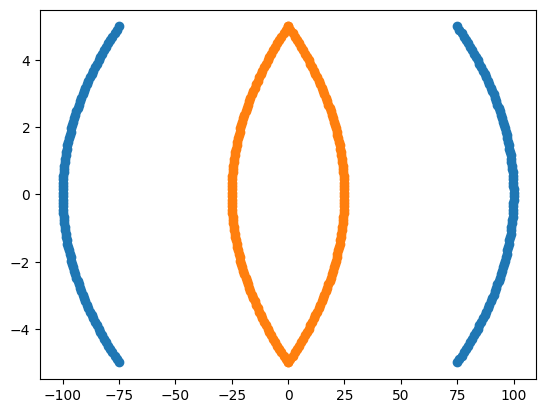

In [ ]:
# --- VIVA NOTE: Plotting the 2D Representation ---
# Scatter plot displaying the non-linear relationship of our coordinates.
# Notice that the orange points (Class 1) are nested inside the blue points (Class 0).
plt.scatter (y,x)
plt.scatter (y1,x1)

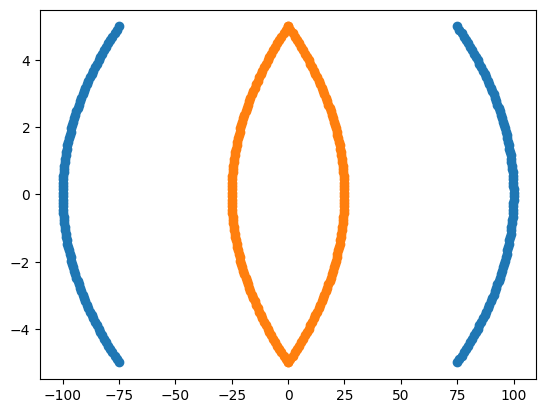

In [ ]:
plt.scatter (y,x)
plt.scatter (y1,x1)

In [ ]:
import pandas as pd

# --- VIVA NOTE: Constructing the Dataset ---
# We combine the generated coordinates into a structured DataFrame.
# 'Y' is our binary target variable (0 for the outer shape, 1 for the inner shape).
df1 = pd.DataFrame(np.vstack([y,x]).T, columns=['X1','X2'])
df1['Y']=0
df2 = pd.DataFrame(np.vstack([y1, x1]).T, columns=['X1','X2'])
df2['Y']=1
df = pd.concat([df1, df2], ignore_index=True)
df.head (5)

,X1,X2,Y
0,75.000000,-5.00000,0
1,75.999898,-4.89899,0
2,76.979390,-4.79798,0
3,77.938476,-4.69697,0
4,78.877155,-4.59596,0


In [ ]:
# --- VIVA NOTE: Feature/Target Separation ---
# X contains the 2D spatial features ('X1', 'X2').
# y contains the ground truth labels ('Y').
x = df.iloc[:, :2]
y = df.Y

In [ ]:
## Split the dataset into train and test
from sklearn.model_selection import train_test_split

# --- VIVA NOTE: Train-Test Split ---
# Splitting the data ensures we evaluate the model's generalization performance
# on unseen testing data, preventing overfitting.
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 0)

In [ ]:
from sklearn.svm import SVC

# --- VIVA NOTE: Linear SVM Attempt ---
# We fit a Support Vector Classifier with a 'linear' kernel.
# A linear kernel tries to find a flat decision boundary (a straight line in 2D).
classifier=SVC(kernel="linear")
classifier.fit(X_train,y_train)

SVC(kernel='linear')

In [ ]:
from sklearn.metrics import accuracy_score

# --- VIVA NOTE: Model Evaluation ---
# The resulting accuracy is extremely low (~46%, worse than random guessing).
# This mathematically proves that a linear decision boundary is incapable of
# separating non-linearly distributed datasets.
y_pred = classifier.predict(X_test)
accuracy_score(y_test, y_pred)

0.46

In [ ]:
# --- VIVA NOTE: Explicit Feature Mapping (The Kernel Trick Theory) ---
# To make the data linearly separable, we map our 2D features [X1, X2] into a
# higher 5D space: [X1, X2, X1^2, X2^2, X1*X2].
# This is the explicit mathematical representation of a 2nd-degree Polynomial Kernel.
# By squaring the features, we transform the parabolic/circular patterns into linear trends.
df ['X1_Square'] = df ['X1']**2
df ['X2_Square'] = df ['X2']**2
df ['X1*X2'] = (df ['X1'] * df ['X2'])
df.head()

,X1,X2,Y,X1_Square,X2_Square,X1*X2
0,75.000000,-5.00000,0,5625.000000,25.000000,-375.000000
1,75.999898,-4.89899,0,5775.984491,24.000102,-372.322732
2,76.979390,-4.79798,0,5925.826463,23.020610,-369.345557
3,77.938476,-4.69697,0,6074.405989,22.061524,-366.074658
4,78.877155,-4.59596,0,6221.605643,21.122845,-362.516219


In [ ]:
# --- VIVA NOTE: Updated Features ---
# We now include our 3 newly engineered higher-dimensional features in the training data.
x = df [['X1', 'X2', 'X1_Square', 'X2_Square', 'X1*X2']]
y = df ['Y']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 0)

In [ ]:
import plotly.express as px

# --- VIVA NOTE: 3D Visualization of Expanded Space ---
# Plotting X1, X2, and the interaction feature X1*X2 in 3D.
# Notice how projecting the data into a third dimension begins to separate the two nested classes.
fig = px.scatter_3d(df, x='X1', y='X2', z='X1*X2', color='Y')
fig.show()

In [ ]:
# --- VIVA NOTE: 3D Visualization using Squared Features ---
# By plotting with X1_Square and the interaction term, we can visually see
# that the classes are now completely separated along the vertical axis.
# This visual separation allows a flat 3D plane (hyperplane) to cleanly split the data.
fig = px.scatter_3d(df, x='X1_Square', y='X1_Square', z='X1*X2', color='Y')
fig.show()

In [ ]:
fig = px.scatter_3d(df, x='X1_Square', y='X1_Square', z='X1*X2', color='Y')
fig.show()

In [ ]:
fig = px.scatter_3d(df, x='X1_Square', y='X1_Square', z='X1*X2', color='Y')
fig.show()

In [ ]:
from sklearn.svm import SVC

# --- VIVA NOTE: Radial Basis Function (RBF) Kernel ---
# Instead of manually expanding features (which is computationally expensive for large datasets),
# we can use the RBF (Gaussian) Kernel.
# The RBF kernel implicitly maps the features into an infinite-dimensional Hilbert space
# using distance metrics, allowing it to easily handle complex, non-linear boundaries.
classifier = SVC(kernel="rbf")
classifier.fit(X_train,y_train)

SVC()